In [8]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/mumbai_cleaned.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (18846, 26)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Description,Property Image,Price_per_m2,Suspicious_Price,Price_num,Area_num,BHK_num,Bathrooms_num,Balconies_num,Furnished_clean
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,93.333333,False,70000.0,750.0,1.0,1.0,NaN,Furnished
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,70.707071,False,140000.0,1980.0,3.0,4.0,4.0,Unfurnished
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,119.346734,False,190000.0,1592.0,3.0,3.0,1.0,Unfurnished
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,84.291188,False,110000.0,1305.0,3.0,3.0,3.0,Unfurnished
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,103.703704,False,140000.0,1350.0,3.0,3.0,NaN,Unfurnished


In [4]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -

In [6]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [3]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nChecking scikit-learn:")
%pip show scikit-learn


Python executable:
c:\Users\nandi\anaconda3\envs\AI-methods-day-1\python.exe

Python version:
3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:14:50) [MSC v.1942 64 bit (AMD64)]

Checking scikit-learn:
Note: you may need to restart the kernel to use updated packages.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("All scikit-learn imports are working!")

All scikit-learn imports are working!


Can we predict monthly rental prices in Mumbai based on property characteristics?

In [9]:
print("Dataset shape:", df.shape)

print("\nAvailable columns:")
for col in df.columns:
    print(col)

print("\nColumn types:")
display(df.dtypes)

Dataset shape: (18846, 26)

Available columns:
Title
Price
Area
BHK
Bathrooms
Furnished
Balconies
Floor
Ownership
Facing
Amenities
Transaction Type
Property Type
Location
Year of Construction
Is Luxury
Description
Property Image
Price_per_m2
Suspicious_Price
Price_num
Area_num
BHK_num
Bathrooms_num
Balconies_num
Furnished_clean

Column types:


Title                       str
Price                   float64
Area                    float64
BHK                     float64
Bathrooms               float64
Furnished                   str
Balconies               float64
Floor                   float64
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type            str
Property Type               str
Location                    str
Year of Construction    float64
Is Luxury                   str
Description                 str
Property Image              str
Price_per_m2            float64
Suspicious_Price           bool
Price_num               float64
Area_num                float64
BHK_num                 float64
Bathrooms_num           float64
Balconies_num           float64
Furnished_clean             str
dtype: object

In [10]:
print(df.columns.tolist())

['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image', 'Price_per_m2', 'Suspicious_Price', 'Price_num', 'Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean']


## 3. Train/Test Split

We split the dataset into 80% training data and 20% test data.

The training set will be used for model training, cross-validation,
and hyperparameter tuning.

The test set will remain untouched until the final evaluation
to assess how well the model generalizes to unseen properties.

In [11]:
from sklearn.model_selection import train_test_split

# Define the target and selected features
target = "Price_num"

features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num",
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

# Verify that all columns exist
assert all(col in df.columns for col in features + [target])

# Keep only rows with a valid target
model_df = df.dropna(subset=[target]).copy()

X = model_df[features]
y = model_df[target]

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (15076, 8)
Testing features: (3770, 8)
Training target: (15076,)
Testing target: (3770,)


## 3. Preprocessing Pipeline

Numerical and categorical features require different preprocessing.

- Numerical features: median imputation and standardization.
- Categorical features: most-frequent imputation and one-hot encoding.

All preprocessing is fitted only on training data through a
scikit-learn pipeline to prevent data leakage.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical and categorical columns
numeric_features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]

categorical_features = [
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## Underfitting and Overfitting Analysis
We investigated underfitting and overfitting using a Decision Tree Regressor to predict monthly rental prices in Mumbai. We varied the maximum tree depth to examine how model complexity affects prediction performance.

At a depth of 1, the model showed signs of underfitting, with high training and validation errors. As the depth increased, validation RMSE decreased, reaching its lowest value at a depth of 5.

Beyond a depth of 5, validation RMSE increased even though training RMSE continued to decrease. This indicates overfitting: the model learns the training data more closely but becomes less effective at predicting unseen properties.

Among the six tree depths tested, a maximum depth of 5 achieved the lowest validation RMSE. We therefore selected it as our current candidate for final evaluation on the held-out test set.

This experiment demonstrates that increasing model complexity does not always improve predictive performance. Selecting an appropriate level of complexity is important for building a model that generalises to unseen rental listings.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Split the training data into a fitting set and a validation set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# Test different levels of model complexity
depths = [1, 2, 3, 5, 10, None]

results = []

for depth in depths:

    # Create a pipeline using our existing preprocessing
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    # Train the model
    model.fit(X_fit, y_fit)

    # Make predictions on training and validation data
    train_predictions = model.predict(X_fit)
    val_predictions = model.predict(X_val)

    # Calculate RMSE for both datasets
    train_rmse = mean_squared_error(
        y_fit, train_predictions
    ) ** 0.5

    val_rmse = mean_squared_error(
        y_val, val_predictions
    ) ** 0.5

    # Calculate R² scores
    train_r2 = r2_score(y_fit, train_predictions)
    val_r2 = r2_score(y_val, val_predictions)

    results.append({
        "Max Depth": str(depth),
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "Training R²": train_r2,
        "Validation R²": val_r2
    })

# Display the results
results_df = pd.DataFrame(results)

display(results_df.round(2))


,Max Depth,Training RMSE,Validation RMSE,Training R²,Validation R²
0,1,103880.85,93969.27,0.39,0.43
1,2,86355.20,82329.78,0.58,0.56
2,3,80549.70,77863.26,0.63,0.61
3,5,76347.14,75265.82,0.67,0.63
4,10,60455.01,79280.67,0.79,0.59
5,None,28752.10,87360.22,0.95,0.50


Plotting the results from the analysis of underfitting and overfitting.

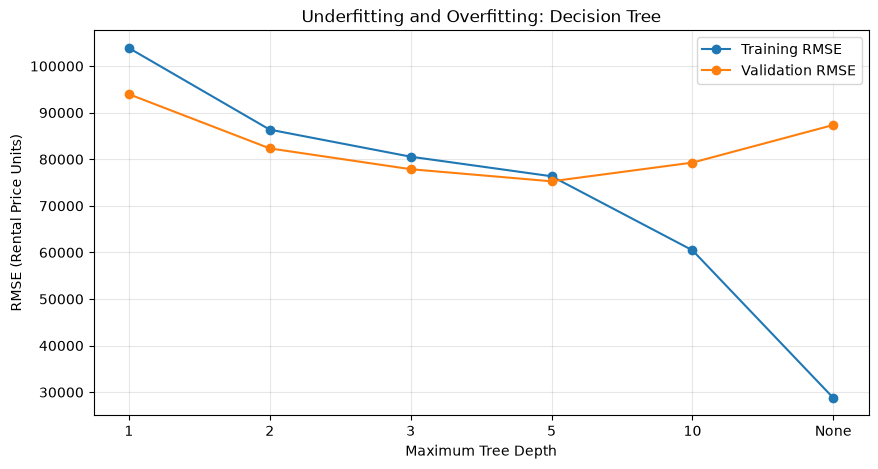

In [14]:
# Plot training and validation errors
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Max Depth"],
    results_df["Training RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    results_df["Max Depth"],
    results_df["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.title("Underfitting and Overfitting: Decision Tree")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (Rental Price Units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Comparison of Model Complexity

We compared three Decision Tree Regressor models with maximum depths of 1, 5, and unlimited depth to investigate underfitting and overfitting.

The model with a depth of 1 showed signs of underfitting, with a training RMSE of 103,880.85 and a validation RMSE of 93,969.27. This indicates that the model was too simple to capture the relationships between property characteristics and rental prices effectively.

The model with a depth of 5 achieved the lowest validation RMSE of 75,265.82. Its training RMSE was 76,347.14, indicating a relatively small difference between training and validation errors.

The unrestricted decision tree achieved a much lower training RMSE of 28,752.10, but its validation RMSE increased to 87,360.22. This indicates overfitting, as the model performed considerably better on the training data than on unseen validation data.

Based on these results, we selected a maximum tree depth of 5 as the best candidate among the three models compared. This experiment demonstrates the importance of controlling model complexity to improve generalisation.

In [15]:
from sklearn.metrics import mean_absolute_error

# Select three model complexities for comparison
comparison_depths = [1, 5, None]

comparison_results = []

for depth in comparison_depths:

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_fit, y_fit)

    train_predictions = model.predict(X_fit)
    val_predictions = model.predict(X_val)

    comparison_results.append({
        "Max Depth": str(depth),
        "Training MAE": mean_absolute_error(
            y_fit, train_predictions
        ),
        "Validation MAE": mean_absolute_error(
            y_val, val_predictions
        ),
        "Training RMSE": mean_squared_error(
            y_fit, train_predictions
        ) ** 0.5,
        "Validation RMSE": mean_squared_error(
            y_val, val_predictions
        ) ** 0.5
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(2))

,Max Depth,Training MAE,Validation MAE,Training RMSE,Validation RMSE
0,1,56492.22,55652.50,103880.85,93969.27
1,5,38684.03,40316.60,76347.14,75265.82
2,None,12619.39,42322.16,28752.10,87360.22


Maximum depth = 5 means we allow the decision tree to grow up to five levels deep, and in our experiment, this gave the lowest validation prediction error among the depths we tested.

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select the best depth based on validation results
best_depth = 5

# Create the final model
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=best_depth,
        random_state=42
    ))
])

# Train on the full original training set
final_model.fit(X_train, y_train)

# Predict rental prices for the unseen test set
test_predictions = final_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(
    y_test, test_predictions
)

test_rmse = mean_squared_error(
    y_test, test_predictions
) ** 0.5

test_r2 = r2_score(
    y_test, test_predictions
)

# Display results
print("Final Model: Decision Tree Regressor")
print("Selected Maximum Depth:", best_depth)
print(f"Test MAE: {test_mae:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R²: {test_r2:.3f}")

Final Model: Decision Tree Regressor
Selected Maximum Depth: 5
Test MAE: 40528.67
Test RMSE: 83764.35
Test R²: 0.611


## Cross-Validation Analysis

We performed 5-fold cross-validation using a Decision Tree Regressor with a maximum depth of 5. The model achieved a mean validation RMSE of 79,945.09, a mean validation MAE of 39,698.33, and a mean validation R² score of 0.628.

The validation RMSE varied across the five folds, ranging from 65,970.28 to 105,663.98. The standard deviation of 16,066.60 indicates that predictive performance was not consistent across all subsets of the training data.

This variation suggests that the model may find some groups of rental properties more difficult to predict than others. Further investigation would be required to identify the reasons for these differences.

Overall, cross-validation provides a broader assessment of model performance than a single validation split. The results support further evaluation of the depth-5 decision tree, while highlighting the need to examine its prediction errors and compare it against a simple baseline model.

In [17]:
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# Create the decision tree model using the existing preprocessing
cv_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

# Perform 5-fold cross-validation on the training data
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    return_train_score=True
)

# Convert negative error scores into positive values
cv_summary = pd.DataFrame({
    "Fold": range(1, 6),
    "Training RMSE": -cv_results["train_rmse"],
    "Validation RMSE": -cv_results["test_rmse"],
    "Training MAE": -cv_results["train_mae"],
    "Validation MAE": -cv_results["test_mae"],
    "Validation R²": cv_results["test_r2"]
})

display(cv_summary.round(2))

print("\nAverage cross-validation results:")
print(f"Mean Validation RMSE: {-cv_results['test_rmse'].mean():.2f}")
print(f"Mean Validation MAE: {-cv_results['test_mae'].mean():.2f}")
print(f"Mean Validation R²: {cv_results['test_r2'].mean():.3f}")

print("\nVariation in validation RMSE:")
print(f"Standard Deviation: {cv_results['test_rmse'].std():.2f}")

,Fold,Training RMSE,Validation RMSE,Training MAE,Validation MAE,Validation R²
0,1,77974.30,67898.84,39119.50,37571.81,0.69
1,2,78180.91,65970.28,39276.84,37939.15,0.68
2,3,73947.16,92112.05,37994.43,41737.87,0.60
3,4,78169.08,68080.29,38860.33,39339.77,0.68
4,5,67366.61,105663.98,37847.37,41903.05,0.49



Average cross-validation results:
Mean Validation RMSE: 79945.09
Mean Validation MAE: 39698.33
Mean Validation R²: 0.628

Variation in validation RMSE:
Standard Deviation: 16066.60


Plotting the folds in Cross-Validation.

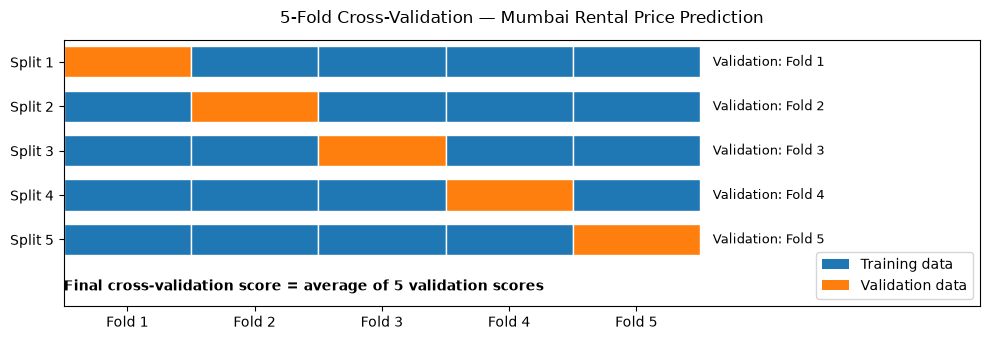

In [20]:
import matplotlib.pyplot as plt

# Number of folds
k = 5

fig, ax = plt.subplots(figsize=(10, 3.5))

# Draw the training and validation folds
for split in range(k):
    for fold in range(k):
        is_validation = fold == split

        ax.barh(
            y=split,
            width=1,
            left=fold,
            height=0.7,
            edgecolor="white",
            color="tab:orange" if is_validation else "tab:blue"
        )

    # Label each validation fold
    ax.text(
        k + 0.1,
        split,
        f"Validation: Fold {split + 1}",
        va="center",
        fontsize=9
    )

# Add the average score annotation
ax.text(
    0,
    k + 0.15,
    "Final cross-validation score = average of 5 validation scores",
    fontweight="bold",
    fontsize=10
)

# Configure axes
ax.set_yticks(range(k))
ax.set_yticklabels([f"Split {i + 1}" for i in range(k)])

ax.set_xticks([i + 0.5 for i in range(k)])
ax.set_xticklabels([f"Fold {i + 1}" for i in range(k)])

ax.invert_yaxis()
ax.set_xlim(0, k + 2.2)
ax.set_ylim(k + 0.5, -0.5)
ax.grid(False)

ax.set_title(
    "5-Fold Cross-Validation — Mumbai Rental Price Prediction",
    fontsize=12,
    pad=12
)

# Add legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="tab:blue", label="Training data"),
    Patch(facecolor="tab:orange", label="Validation data")
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True
)

plt.tight_layout()
plt.show()

## Baseline Model Comparison

To evaluate whether using property characteristics improves rental-price prediction, we compared our Decision Tree Regressor with a baseline model that predicts the median rental price from the training data for every property.

The baseline achieved a test MAE of 67,123.75, a test RMSE of 140,522.95, and an R² score of -0.095.

In comparison, our Decision Tree with a maximum depth of 5 achieved a test MAE of 40,528.67, a test RMSE of 83,764.35, and an R² score of 0.611.

Compared with the baseline, the Decision Tree reduced MAE by approximately 39.6% and RMSE by approximately 40.4%. It also achieved a substantially higher R² score.

These results suggest that property characteristics provide useful information for predicting rental prices in our dataset. However, the remaining prediction errors indicate that the model could still be improved.

In [18]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Create a simple baseline model
baseline_model = DummyRegressor(strategy="median")

# Train the baseline using the original training data
baseline_model.fit(X_train, y_train)

# Predict prices for the original test data
baseline_predictions = baseline_model.predict(X_test)

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = mean_squared_error(
    y_test, baseline_predictions
) ** 0.5

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Display results
print("Baseline Model: Median Prediction")
print(f"Test MAE: {baseline_mae:.2f}")
print(f"Test RMSE: {baseline_rmse:.2f}")
print(f"Test R²: {baseline_r2:.3f}")

Baseline Model: Median Prediction
Test MAE: 67123.75
Test RMSE: 140522.95
Test R²: -0.095


In [19]:
# Compare the baseline and Decision Tree on the same test set
comparison_test = pd.DataFrame({
    "Model": [
        "Baseline (Median)",
        "Decision Tree (Depth 5)"
    ],
    "Test MAE": [
        baseline_mae,
        test_mae
    ],
    "Test RMSE": [
        baseline_rmse,
        test_rmse
    ],
    "Test R²": [
        baseline_r2,
        test_r2
    ]
})

display(comparison_test.round(3))

,Model,Test MAE,Test RMSE,Test R²
0,Baseline (Median),67123.754,140522.950,-0.095
1,Decision Tree (Depth 5),40528.666,83764.353,0.611


Inspecting Available Columns

In [21]:
# Display all columns in the original dataset
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image', 'Price_per_m2', 'Suspicious_Price', 'Price_num', 'Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean']


## Data Leakage Check

Our target variable is `Price_num`, which represents the rental price we want to predict.

We checked the eight features used by our Decision Tree Regressor and confirmed that the following columns are excluded from the model: `Price`, `Price_num`, `Price_per_m2`, and `Suspicious_Price`.

This is important because `Price_per_m2` may be calculated using the rental price, while `Suspicious_Price` may encode information derived from the target. Including such features could allow the model to access information that would not be available when predicting rent for a new property.

Our model instead uses property characteristics such as area, number of bedrooms, bathrooms, balconies, furnishing, facing, location, and property type.

This check confirms that the identified columns are not directly included in the model. Further checks of feature creation and preprocessing are still necessary to establish that the complete workflow is free from data leakage.

Investigating Potential Data Leakage

In [22]:
import numpy as np
import pandas as pd

# Check the relationship between price, area, and price per square metre
leakage_check = df[
    ["Price_num", "Area_num", "Price_per_m2"]
].copy()

# Remove rows with missing or invalid values
leakage_check = leakage_check.dropna()

# Avoid division by zero
leakage_check = leakage_check[
    (leakage_check["Area_num"] > 0) &
    (leakage_check["Price_num"] > 0)
]

# Calculate price per square metre from the target and area
leakage_check["Calculated_Price_per_m2"] = (
    leakage_check["Price_num"] / leakage_check["Area_num"]
)

# Compare the calculated value with the existing feature
leakage_check["Difference"] = (
    leakage_check["Price_per_m2"] -
    leakage_check["Calculated_Price_per_m2"]
).abs()

print("Number of rows checked:", len(leakage_check))

print(
    "Mean absolute difference:",
    leakage_check["Difference"].mean()
)

print(
    "Maximum absolute difference:",
    leakage_check["Difference"].max()
)

display(leakage_check.head())

Number of rows checked: 18846
Mean absolute difference: 1.8131404145130567e-15
Maximum absolute difference: 1.1368683772161603e-13


,Price_num,Area_num,Price_per_m2,Calculated_Price_per_m2,Difference
0,70000.0,750.0,93.333333,93.333333,1.421085e-14
1,140000.0,1980.0,70.707071,70.707071,0.000000e+00
2,190000.0,1592.0,119.346734,119.346734,0.000000e+00
3,110000.0,1305.0,84.291188,84.291188,1.421085e-14
4,140000.0,1350.0,103.703704,103.703704,1.421085e-14


Compare model performance with and without the potential leakage feature

In [23]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Compare the existing features with a version excluding Price_per_m2
X_train_with = X_train.copy()
X_test_with = X_test.copy()

X_train_without = X_train.drop(
    columns=["Price_per_m2"],
    errors="ignore"
)

X_test_without = X_test.drop(
    columns=["Price_per_m2"],
    errors="ignore"
)

# Reuse the same preprocessing and model settings.
# Rebuild the preprocessing pipeline for each feature set if needed.
print("Training features with potential leakage:", X_train_with.shape[1])
print("Training features without Price_per_m2:", X_train_without.shape[1])

Training features with potential leakage: 8
Training features without Price_per_m2: 8


In [24]:
print("Features used by our model:")
print(X_train.columns.tolist())

print("\nIs Price_per_m2 in X_train?")
print("Price_per_m2" in X_train.columns)

print("\nNumber of features:", len(X_train.columns))

Features used by our model:
['Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean', 'Facing', 'Location', 'Property Type']

Is Price_per_m2 in X_train?
False

Number of features: 8


In [25]:
# Check the relationship between the target and our input features

print("Target variable:", y_train.name)

print("\nFeatures used for prediction:")
for column in X_train.columns:
    print("-", column)

print("\nChecking for target leakage:")

# Features that should not be used if they are derived from the target
potential_leakage_features = [
    "Price",
    "Price_num",
    "Price_per_m2",
    "Suspicious_Price"
]

for feature in potential_leakage_features:
    if feature in X_train.columns:
        print(f"WARNING: {feature} is included in the training features.")
    else:
        print(f"OK: {feature} is not included in the training features.")

Target variable: Price_num

Features used for prediction:
- Area_num
- BHK_num
- Bathrooms_num
- Balconies_num
- Furnished_clean
- Facing
- Location
- Property Type

Checking for target leakage:
OK: Price is not included in the training features.
OK: Price_num is not included in the training features.
OK: Price_per_m2 is not included in the training features.
OK: Suspicious_Price is not included in the training features.
